In [1]:
%%markdown

# Линейные методы

## Конфигурация окружения.



# Линейные методы

## Конфигурация окружения.


In [2]:
%cd %pwd/../../

Z:\.ITMO\sem_05\andan\labs\001\src


In [3]:
%%markdown

### Библиотеки

`sklearn` - только для загрузки и разбиения датасета, банальный `matplotlib` для вывода, отдельная математика из `scipy`.



### Библиотеки

`sklearn` - только для загрузки и разбиения датасета, банальный `matplotlib` для вывода, отдельная математика из `scipy`.


In [4]:
from pathlib import Path
import dataclasses
from dataclasses import dataclass, field
from typing import Callable

import numpy as np
from scipy.special import expit
from scipy import stats

import matplotlib.pyplot as plt

from sklearn.datasets import load_svmlight_file
from sklearn.model_selection import train_test_split

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["axes.grid"] = True

In [5]:
from IPython.display import display
_ = get_ipython().display_formatter.formatters['text/plain'].for_type(str, lambda string, pp, _: pp.text(string))

In [6]:
%%markdown

### Загрузка датасета

Я взял датасет с курса методов оптимизации, в нём немного признаков и он разумного размера.



### Загрузка датасета

Я взял датасет с курса методов оптимизации, в нём немного признаков и он разумного размера.


In [7]:
DATA_PATH = Path("./datasets/ijcnn1.txt.bz2")

@dataclass
class Dataset:
    X: np.ndarray
    y: np.ndarray

def load_dataset(path: Path) -> Dataset:
    X_sparse, y = load_svmlight_file(path)
    return Dataset(X_sparse.toarray().astype(np.float64), y.astype(np.float64))

DATA = load_dataset(DATA_PATH)

f"""Shape {DATA.X.shape}
classes {np.unique(DATA.y)}, class balance {np.bincount((DATA.y > 0).astype(int))}"""

Shape (49990, 22)
classes [-1.  1.], class balance [45137  4853]

In [8]:
%%markdown

### Разбиение датасета и проверка



### Разбиение датасета и проверка


In [9]:
RANDOM_STATE: int = 30

def split(test_size: float, *, data: Dataset = DATA, seed: int = RANDOM_STATE) -> tuple[Dataset, Dataset]:
    from sklearn.model_selection import train_test_split

    X_train, X_test, y_train, y_test = train_test_split(
        data.X, data.y, test_size=test_size, stratify=data.y, random_state=seed,
    )

    mu = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1.0

    X_train = (X_train - mu) / sigma
    X_test = (X_test - mu) / sigma

    return Dataset(X_train, y_train), Dataset(X_test, y_test)

train, test = split(0.2)

f"""Train:
  Shape {train.X.shape}, class balance {np.bincount((train.y > 0).astype(int))}
Test:
  Shape {test.X.shape}, class balance {np.bincount((test.y > 0).astype(int))}
"""

Train:
  Shape (39992, 22), class balance [36110  3882]
Test:
  Shape (9998, 22), class balance [9027  971]


In [10]:
%%markdown

### Функции качества/ошибки

Банальное количество совпадений как точность.



### Функции качества/ошибки

Банальное количество совпадений как точность.


In [11]:
def accuracy(y_true: np.ndarray, y_score: np.ndarray) -> float:
    return float(np.mean(np.sign(y_score) == y_true))

def error(y_true: np.ndarray, y_score: np.ndarray) -> float:
    return 1.0 - accuracy(y_true, y_score)

In [12]:
%%markdown

## Алгоритмы

### Линейная регрессия (с гребневой регуляризацией) в матричном виде

Это просто решение уравнения $\text{weights} = (X^\top X + \alpha I)^{-1} X^\top y$,
где $+ \alpha I$ - гребневая регуляризация, стягивающая коэффициенты к нулю.

Там какие-то сложности с тем, хотим ли мы регуляризовать константное смещение.


## Алгоритмы

### Линейная регрессия (с гребневой регуляризацией) в матричном виде

Это просто решение уравнения $\text{weights} = (X^\top X + \alpha I)^{-1} X^\top y$,
где $+ \alpha I$ - гребневая регуляризация, стягивающая коэффициенты к нулю.

Там какие-то сложности с тем, хотим ли мы регуляризовать константное смещение.


In [13]:
class LinearRegression:
    def __init__(self, alpha: float = 1.0, penalize_intercept: bool = True):
        self.alpha = alpha
        self.penalize_intercept = penalize_intercept
        self.coef_: np.ndarray | None = None
        self.intercept_: float | None = None

    def fit(self, data: Dataset) -> None:
        X, y = data.X, data.y
        n, d = X.shape
        X_aug = np.hstack([np.ones((n, 1)), X])

        A = X_aug.T @ X_aug
        b = X_aug.T @ y

        penalty = self.alpha * np.eye(d + 1)
        if not self.penalize_intercept:
            penalty[0, 0] = 0.0

        theta = np.linalg.solve(A + penalty, b)
        self.intercept_ = float(theta[0])
        self.coef_ = theta[1:]

    def decision_function(self, X: np.ndarray) -> np.ndarray:
        return X @ self.coef_ + self.intercept_

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.sign(self.decision_function(X))

In [14]:
def verify():
    from sklearn.linear_model import Ridge

    rng = np.random.default_rng(0)
    X = rng.normal(size=(200, 5))
    y = X @ np.array([1.0, -2.0, 0.5, 0.0, 3.0]) + 0.4 + rng.normal(0, 0.1, 200)
    synth = Dataset(X, y)

    for alpha in [0.01, 1.0, 100.0]:
        ours = LinearRegression(alpha=alpha, penalize_intercept=False)
        ours.fit(synth)
        sk = Ridge(alpha=alpha).fit(X, y)

        coeff_distance = np.max(np.abs(np.r_[ours.intercept_, ours.coef_] - np.r_[sk.intercept_, sk.coef_]))
        print(f"alpha = {alpha}: max|Δ| = {coeff_distance:.2e}")

verify()

alpha = 0.01: max|Δ| = 1.33e-15
alpha = 1.0: max|Δ| = 4.44e-16
alpha = 100.0: max|Δ| = 6.66e-16


In [15]:
def test(alpha, test_size):
    train, test = split(test_size)

    clf = LinearRegression(alpha)
    clf.fit(train)

    result_train = clf.decision_function(train.X)
    result_test = clf.decision_function(test.X)

    print(f"alpha = {alpha}, test = {test_size:.0%}: train error = {error(train.y, result_train):.3%}, test error = {error(test.y, result_test):.3%}")

for alpha in [0.01, 1.0, 100.0]:
    for test_size in [0.1, 0.2, 0.3]:
        test(alpha, test_size)

alpha = 0.01, test = 10%: train error = 8.451%, test error = 8.322%
alpha = 0.01, test = 20%: train error = 8.472%, test error = 8.242%
alpha = 0.01, test = 30%: train error = 8.476%, test error = 8.322%
alpha = 1.0, test = 10%: train error = 8.451%, test error = 8.322%
alpha = 1.0, test = 20%: train error = 8.472%, test error = 8.242%
alpha = 1.0, test = 30%: train error = 8.476%, test error = 8.322%
alpha = 100.0, test = 10%: train error = 8.453%, test error = 8.342%
alpha = 100.0, test = 20%: train error = 8.472%, test error = 8.262%
alpha = 100.0, test = 30%: train error = 8.476%, test error = 8.348%


In [16]:
%%markdown

### Линейная классификация на основе градиентного спуска

Вместо точного решения довольно простой задачи здесь итеративно приближается более сложная задача - 
не просто минимизируем разницу предсказания и ответа, а используем отступ и накладываем поверх него риск.

Отступ (`M = y * (X @ w + b)`): он $>0$ при верном направлении и $<0$ при неверном, модуль растёт с "уверенностью".

Выбранные риски:
- logistic: $\log(1+e^{-M})$ -> $-\sigma(-M)$
- hinge: $\max(0, 1-M)$ -> $-\mathbb{1}[M<1]$
- hinge^2: $\max(0, 1-M)^2$ -> $-2(1-M)\mathbb{1}[M<1]$

Elastic Net:
- `self.params.lambda1 * np.sign(w)` - двигает к нулю вообще независимо от весов
- `2.0 * self.params.lambda2 * w` - двигает к нулю пропорционально весам




### Линейная классификация на основе градиентного спуска

Вместо точного решения довольно простой задачи здесь итеративно приближается более сложная задача - 
не просто минимизируем разницу предсказания и ответа, а используем отступ и накладываем поверх него риск.

Отступ (`M = y * (X @ w + b)`): он $>0$ при верном направлении и $<0$ при неверном, модуль растёт с "уверенностью".

Выбранные риски:
- logistic: $\log(1+e^{-M})$ -> $-\sigma(-M)$
- hinge: $\max(0, 1-M)$ -> $-\mathbb{1}[M<1]$
- hinge^2: $\max(0, 1-M)^2$ -> $-2(1-M)\mathbb{1}[M<1]$

Elastic Net:
- `self.params.lambda1 * np.sign(w)` - двигает к нулю вообще независимо от весов
- `2.0 * self.params.lambda2 * w` - двигает к нулю пропорционально весам



In [17]:
LossFn = Callable[[np.ndarray], np.ndarray]
Risk = tuple[LossFn, LossFn]

LOGISTIC: Risk = (
    lambda M: np.logaddexp(0.0, -M),
    lambda M: -expit(-M),
)
HINGE: Risk = (
    lambda M: np.maximum(0.0, 1.0 - M),
    lambda M: -np.where(M < 1.0, 1.0, 0.0),
)
SQR_HINGE: Risk = (
    lambda M: np.maximum(0.0, 1.0 - M) ** 2,
    lambda M: -2.0 * np.where(M < 1.0, 1.0 - M, 0.0),
)

LOSSES: dict[str, Risk] = {"logistic": LOGISTIC, "hinge": HINGE, "sqr_hinge": SQR_HINGE}

In [18]:
@dataclass
class GDParams:
    learning_rate: float = 0.1
    lambda1: float = 0.0
    lambda2: float = 0.0
    max_iter: int = 1000
    tol: float = 1e-7


@dataclass
class History:
    empirical_risk: list[float] = field(default_factory=list)
    objective: list[float] = field(default_factory=list)


Callback = Callable[[int, np.ndarray, float], None]


class GDClassifier:
    def __init__(self, loss: Risk, params: GDParams | None = None):
        self.loss = loss
        self.params = params or GDParams()
        self.coef_: np.ndarray | None = None
        self.intercept_: float = 0.0
        self.history_: History = History()

    def _gradient(self, X, y, w, b):
        loss_fn, grad_fn = self.loss

        M = y * (X @ w + b)
        emp = loss_fn(M).mean()

        reg = self.params.lambda1 * np.abs(w).sum() + self.params.lambda2 * (w @ w)
        dz = grad_fn(M) * y

        grad_w = (X.T @ dz) / len(y) + self.params.lambda1 * np.sign(w) + 2.0 * self.params.lambda2 * w
        grad_b = dz.mean()

        return grad_w, grad_b, emp, reg

    def fit_step(self, X, y, w, b):
        grad_w, grad_b, emp, reg = self._gradient(X, y, w, b)
        w = w - self.params.learning_rate * grad_w
        b = b - self.params.learning_rate * grad_b
        return w, b, emp, reg

    def fit(self, data: Dataset, callback: Callback | None = None) -> None:
        X, y = data.X, data.y
        w, b = np.zeros(X.shape[1]), 0.0

        history = History()
        prev_obj = np.inf

        for it in range(self.params.max_iter):
            w, b, emp, reg = self.fit_step(X, y, w, b)
            obj = emp + reg

            history.empirical_risk.append(emp)
            history.objective.append(obj)
            if callback is not None:
                callback(it, w, b)

            if abs(prev_obj - obj) < self.params.tol:
                break

            prev_obj = obj

        self.coef_ = w
        self.intercept_ = b
        self.history_ = history

    def decision_function(self, X: np.ndarray) -> np.ndarray:
        return X @ self.coef_ + self.intercept_

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.where(self.decision_function(X) >= 0.0, 1.0, -1.0)

In [19]:
def test(loss_name, loss, lr, test_size):
    train, test = split(test_size)

    clf = GDClassifier(loss, GDParams(learning_rate=lr, max_iter=1000))
    clf.fit(train)

    result_train = clf.decision_function(train.X)
    result_test = clf.decision_function(test.X)

    print(f"loss = {loss_name}, lr = {lr}, test = {test_size:.0%}: iters = {len(clf.history_.objective):4d}, "
          f"train error = {error(train.y, result_train):.3%}, test error = {error(test.y, result_test):.3%}")

for loss_name, loss in LOSSES.items():
    for lr in [0.1, 0.5, 1.0]:
        test(loss_name, loss, lr, 0.2)

loss = logistic, lr = 0.1, test = 20%: iters = 1000, train error = 7.854%, test error = 7.682%
loss = logistic, lr = 0.5, test = 20%: iters = 1000, train error = 7.509%, test error = 7.592%
loss = logistic, lr = 1.0, test = 20%: iters =  682, train error = 7.494%, test error = 7.562%
loss = hinge, lr = 0.1, test = 20%: iters = 1000, train error = 7.959%, test error = 7.832%
loss = hinge, lr = 0.5, test = 20%: iters =  640, train error = 7.529%, test error = 7.441%
loss = hinge, lr = 1.0, test = 20%: iters =  351, train error = 7.517%, test error = 7.431%
loss = sqr_hinge, lr = 0.1, test = 20%: iters =  489, train error = 7.704%, test error = 7.532%
loss = sqr_hinge, lr = 0.5, test = 20%: iters =  118, train error = 7.684%, test error = 7.562%
loss = sqr_hinge, lr = 1.0, test = 20%: iters = 1000, train error = 7.917%, test error = 7.802%


In [20]:
%%markdown

## Задания

### Подбор гиперпараметров



## Задания

### Подбор гиперпараметров


In [21]:
def _grid_search(make_model, param_grid, data: Dataset, n_splits: int = 3, seed: int = 30):
    from joblib import Parallel, delayed
    from sklearn.model_selection import ParameterGrid, StratifiedKFold

    def normalize(tr: Dataset, va: Dataset) -> tuple[Dataset, Dataset]:
        mu = tr.X.mean(axis=0)
        sigma = tr.X.std(axis=0)
        sigma[sigma == 0] = 1.0

        return (
            Dataset((tr.X - mu) / sigma, tr.y),
            Dataset((va.X - mu) / sigma, va.y),
        )

    def evaluate_params(params):
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        scores = []

        for tr_idx, va_idx in skf.split(data.X, data.y):
            tr, va = normalize(
                Dataset(data.X[tr_idx], data.y[tr_idx]),
                Dataset(data.X[va_idx], data.y[va_idx]),
            )

            model = make_model(**params)
            model.fit(tr)
            scores.append(error(va.y, model.decision_function(va.X)))

        return params, float(np.mean(scores)), float(np.std(scores))

    results = Parallel(n_jobs=-1)(
        delayed(evaluate_params)(params) for params in ParameterGrid(param_grid)
    )
    
    return sorted(results, key=lambda x: x[1])


def grid_search_regression() -> float:
    results = _grid_search(
        lambda alpha: LinearRegression(alpha=alpha),
        {"alpha": np.logspace(-3, 3, 21)},
        DATA,
    )

    print("Ridge, top-5:")
    for p, m, s in results[:5]:
        print(f"  alpha={p['alpha']:.2e}: error={m:.8%} ± {s:.8%}")

    return results[0][0]

def grid_search_gdclassification() -> tuple[Risk, GDParams]:
    param_grid = {
        "loss_name": list(LOSSES.keys()),
        "lr": np.logspace(-2, 0, 3),
        "l1": np.r_[0.0, np.logspace(-4, -2, 3)],
        "l2": np.r_[0.0, np.logspace(-4, -2, 3)],
    }

    def make_params(loss_name, lr, l1, l2) -> GDParams:
        return GDParams(learning_rate=lr, lambda1=l1, lambda2=l2, max_iter=200)

    def make_model(**kwargs) -> GDClassifier:
        return GDClassifier(LOSSES[kwargs['loss_name']], make_params(**kwargs))

    results = _grid_search(make_model, param_grid, DATA)

    print("\nGD, top-5:")
    for p, m, s in results[:5]:
        print(f"  {p['loss_name']} lr={p['lr']:.2f} l1={p['l1']:.0e} l2={p['l2']:.0e}: error={m:.6%} ± {s:.6%}")

    best = results[0][0]
    return (LOSSES[best['loss_name']], make_params(**best))

BEST_REGRESSION = grid_search_regression()
BEST_GDCLASSIFICATION = grid_search_gdclassification()

Ridge, top-5:
  alpha=1.00e-03: error=8.42768738% ± 0.12187397%
  alpha=2.00e-03: error=8.42768738% ± 0.12187397%
  alpha=3.98e-03: error=8.42768738% ± 0.12187397%
  alpha=7.94e-03: error=8.42768738% ± 0.12187397%
  alpha=1.58e-02: error=8.42768738% ± 0.12187397%

GD, top-5:
  hinge lr=1.00 l1=1e-04 l2=0e+00: error=7.629530% ± 0.158712%
  hinge lr=1.00 l1=0e+00 l2=0e+00: error=7.629531% ± 0.171384%
  hinge lr=1.00 l1=1e-04 l2=1e-04: error=7.633532% ± 0.171079%
  hinge lr=1.00 l1=0e+00 l2=1e-04: error=7.635532% ± 0.171524%
  logistic lr=1.00 l1=0e+00 l2=0e+00: error=7.691542% ± 0.122745%


In [22]:
%%markdown

### Кривая эмпирического риска



### Кривая эмпирического риска


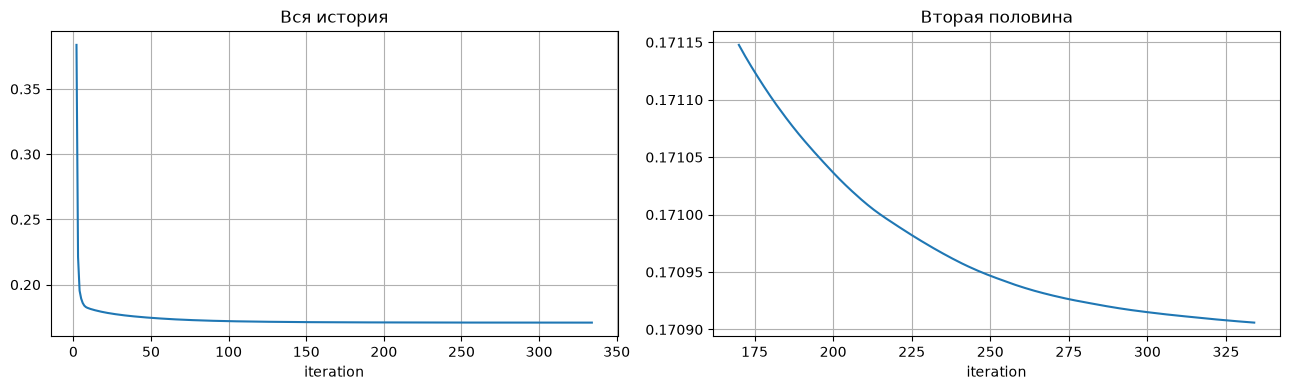

In [23]:
AVERAGE_WINDOW_EXTENT = 2

def moving_average(x: np.ndarray) -> np.ndarray:
    window = AVERAGE_WINDOW_EXTENT * 2 + 1

    kernel = np.ones(window) / window
    return np.convolve(x, kernel, mode="valid")

def risk_curve():
    train, test = split(0.2)

    clf = GDClassifier(BEST_GDCLASSIFICATION[0], dataclasses.replace(BEST_GDCLASSIFICATION[1], max_iter=1000))
    clf.fit(train)

    risk = np.asarray(clf.history_.empirical_risk)
    smoothed = moving_average(risk)
    half = len(risk) // 2

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    off = AVERAGE_WINDOW_EXTENT
    axes[0].plot(np.arange(off, len(risk) - off), smoothed)
    axes[0].set_xlabel("iteration")
    axes[0].set_title("Вся история")

    axes[1].plot(np.arange(half + off, len(risk) - off), smoothed[half:])
    axes[1].set_xlabel("iteration")
    axes[1].set_title("Вторая половина")

    plt.tight_layout()
    plt.show()

risk_curve()

In [24]:
%%markdown

### Кривая функции ошибки



### Кривая функции ошибки


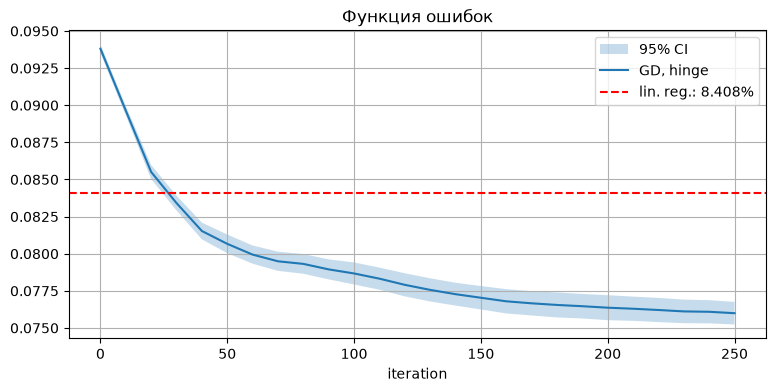

In [25]:
ERROR_SEED_SAMPLES = 20
ERROR_SAMPLE_INTERVAL = 10

def error_curve():
    gd_errors, lin_reg_errors = [], []
    for seed in range(ERROR_SEED_SAMPLES):
        train, test = split(0.2, seed=seed)

        errors = []
        def record(it, w, b):
            if not it % ERROR_SAMPLE_INTERVAL:
                errors.append(error(test.y, test.X @ w + b))

        GDClassifier(BEST_GDCLASSIFICATION[0], dataclasses.replace(BEST_GDCLASSIFICATION[1], max_iter=251, tol=0.0)).fit(train, callback=record)
        gd_errors.append(errors)

        lin_reg = LinearRegression(**BEST_REGRESSION)
        lin_reg.fit(train)
        lin_reg_errors.append(error(test.y, lin_reg.decision_function(test.X)))

    curves = np.array(gd_errors)
    mean, sem = curves.mean(axis=0), stats.sem(curves, axis=0)
    lo, hi = stats.t.interval(0.95, df=ERROR_SEED_SAMPLES - 1, loc=mean, scale=sem)
    iters = np.arange(len(mean)) * ERROR_SAMPLE_INTERVAL

    plt.figure(figsize=(9, 4))
    plt.fill_between(iters, lo, hi, alpha=0.25, label="95% CI")
    plt.plot(iters, mean, label="GD, hinge")
    plt.axhline(np.mean(lin_reg_errors), color="red", linestyle="--", label=f"lin. reg.: {np.mean(lin_reg_errors):.3%}")
    plt.xlabel("iteration")
    plt.title(f"Функция ошибок")
    plt.legend()
    plt.show()

error_curve()

In [26]:
%%markdown

### График(и) коэффициентов модели от L1/L2



### График(и) коэффициентов модели от L1/L2


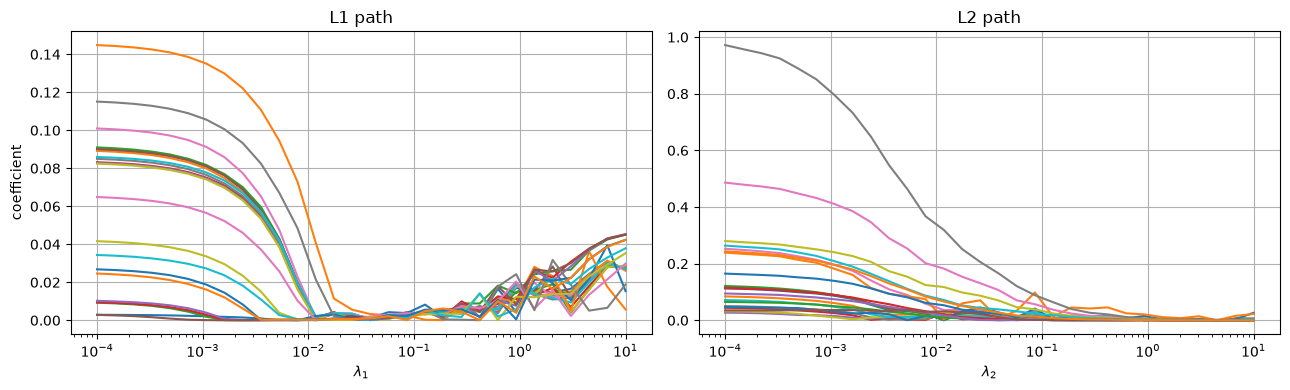

In [27]:
L1_LAMBDAS = np.logspace(-4, 1, 30)
L2_LAMBDAS = np.logspace(-4, 1, 30)

def _coef(params_fn, lam):
    clf = GDClassifier(HINGE, params_fn(lam))
    clf.fit(DATA)
    return clf.coef_

def _coef_path(params_fn, lambdas):
    return np.array([_coef(params_fn, lam) for lam in lambdas])

def coef_paths():
    l1 = _coef_path(lambda lam: GDParams(learning_rate=0.05 / (1.0 + lam), lambda1=lam, lambda2=0.0, max_iter=200), L1_LAMBDAS)
    l2 = _coef_path(lambda lam: GDParams(learning_rate=1.0  / (1.0 + lam), lambda1=0.0, lambda2=lam, max_iter=200), L2_LAMBDAS)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    for j in range(l1.shape[1]):
        axes[0].plot(L1_LAMBDAS, np.abs(l1[:, j]))
        axes[1].plot(L2_LAMBDAS, np.abs(l2[:, j]))

    axes[0].set_xscale("log")
    axes[0].set_xlabel(r"$\lambda_1$")
    axes[0].set_ylabel("coefficient")
    axes[0].set_title("L1 path")

    axes[1].set_xscale("log")
    axes[1].set_xlabel(r"$\lambda_2$")
    axes[1].set_title("L2 path")

    plt.tight_layout()
    plt.show()

coef_paths()